# 05. A/B-тест: скидка 10%

**Гипотеза.** Скидка 10% на все заказы увеличит долю клиентов, совершающих покупку, настолько, что выручка на клиента не упадёт, несмотря на более низкие цены.

**Дизайн** (зафиксирован до запуска, реестр - `dbt/seeds/experiments.csv`):
- единица рандомизации - клиент; группа назначается детерминированным хэшем `md5(experiment_id:клиент)`, 50/50;
- участвуют все клиенты (intention-to-treat): зарегистрированные раньше - с момента старта, новые - с момента регистрации;
- длительность 42 дня = 6 полных недель, чтобы недельная сезонность (ноутбук 01) одинаково попала в обе группы;
- уровень значимости 5%, тесты двусторонние.

**Метрики:**

| Роль | Метрика | Тип | Метод |
|---|---|---|---|
| Основная | конверсия - доля клиентов хотя бы с одной покупкой в окне | доля | z-тест, интервал Ньюкомба |
| Вторичная | ARPU - выручка на участника (включая не купивших) | среднее, тяжёлый хвост | Уэлч, бутстреп, CUPED |
| Вторичная | средний чек - выручка / число покупок | отношение | delta-метод |
| Guardrail | доля отмен - отменённые / все заказы | отношение | delta-метод |

**Правило решения (до запуска):** внедряем, если конверсия значимо выросла и ARPU значимо не упал. Решение принимается по основной метрике; вторичные метрики не превращаются в «ещё один шанс найти значимость» - это защита от множественного тестирования.

**Данные:** `marts.mart_ab_users` - одна строка на участника с метриками в окне эксперимента и в предпериоде той же длины.

In [1]:
import sys
sys.path.insert(0, "..")  # модуль analytics лежит в корне репозитория

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analytics.db import query
from analytics.plots import setup, money_axis, percent_axis, BLUE, ORANGE, AQUA, YELLOW, GRAY, SERIES

setup()
pd.set_option("display.float_format", "{:,.2f}".format)

from scipy import stats as st
from analytics import stats as ab

In [2]:
users = query("select * from mart_ab_users where experiment_id = 'discount_10'")
start, end = users.window_start.min(), users.window_end.max()
control, treatment = users[users.variant == "control"], users[users.variant == "treatment"]

print(f"Окно эксперимента: {start:%d.%m.%Y %H:%M} - {end:%d.%m.%Y %H:%M} UTC ({(end - start).days} дней)")
print(f"Участников: control {len(control):,}, treatment {len(treatment):,}; "
      f"новых клиентов (пришли во время теста): {users.is_new_customer.mean():.1%}")

Окно эксперимента: 17.09.2026 08:05 - 29.10.2026 08:05 UTC (42 дней)
Участников: control 3,391, treatment 3,441; новых клиентов (пришли во время теста): 29.0%


## 1. Дизайн: какой эффект тест способен заметить

Так тест планируется **до** запуска - по историческим данным. Берём предыдущие 42 дня перед стартом как «репетицию»: какой была бы конверсия и разброс выручки на клиента, и считаем минимальный обнаружимый эффект (MDE) при мощности 80%.

Для CUPED нужна ещё корреляция метрики с той же метрикой за предыдущий период; её тоже оцениваем на истории: окно [-84; -42) дней против [-42; 0).

In [3]:
orders = query("select customer_id, created_at, order_total from fct_orders where is_revenue")
customers = query("select customer_id, created_at from dim_customers")
window = pd.Timedelta(days=42)

def window_metrics(t0, t1, population_before):
    """Выручка и покупки клиентов в окне [t0, t1) для всех, кто зарегистрирован до population_before."""
    pop = customers.loc[customers.created_at < population_before, "customer_id"]
    o = orders[(orders.created_at >= t0) & (orders.created_at < t1)]
    agg = o.groupby("customer_id").order_total.agg(purchases="size", revenue="sum")
    return pd.DataFrame(index=pd.Index(pop, name="customer_id")).join(agg).fillna(0)

rehearsal = window_metrics(start - window, start, start)
previous = window_metrics(start - 2 * window, start - window, start)
rho = np.corrcoef(rehearsal.revenue, previous.revenue)[0, 1]

p0 = (rehearsal.purchases > 0).mean()
arpu0, std0 = rehearsal.revenue.mean(), rehearsal.revenue.std()
n = len(users) // 2

plan = pd.DataFrame({
    "База": [p0, arpu0, arpu0],
    "Ст. откл.": [np.sqrt(p0 * (1 - p0)), std0, std0 * np.sqrt(1 - rho ** 2)],
    "MDE абс.": [ab.mde_proportion(p0, n), ab.mde_mean(std0, n), ab.mde_mean(std0 * np.sqrt(1 - rho ** 2), n)],
}, index=["Конверсия", "ARPU", "ARPU с CUPED"])
plan["MDE отн."] = plan["MDE абс."] / plan["База"]
print(f"Участников на группу ~{n:,}; корреляция выручки соседних окон rho = {rho:.2f}, "
      f"CUPED снизит дисперсию на {rho ** 2:.0%}")
plan.style.format({"База": "{:,.3f}", "Ст. откл.": "{:,.3f}", "MDE абс.": "{:,.3f}", "MDE отн.": "{:.1%}"})

Участников на группу ~3,416; корреляция выручки соседних окон rho = 0.09, CUPED снизит дисперсию на 1%


,База,Ст. откл.,MDE абс.,MDE отн.
Конверсия,0.480,0.500,0.034,7.1%
ARPU,729.892,"1,460.018",98.973,13.6%
ARPU с CUPED,729.892,"1,454.490",98.599,13.5%


Конверсия обнаружима при эффекте от нескольких процентов, а для ARPU MDE заметно больше: выручка на клиента - это много нулей и длинный хвост. Это нужно знать до запуска: если ARPU не окажется значимым, это не «эффекта нет», а «тест не способен увидеть эффект такого размера».

CUPED здесь почти бесполезен: выручка соседних 42-дневных окон у одного клиента почти не коррелирует (rho около 0.1), потому что покупки редкие - за окно у большинства 0-1 покупка. CUPED хорошо работает на метриках, стабильных у пользователя (время в приложении, число сессий, регулярные покупки). Здесь помогли бы ковариаты с большей предсказательной силой - например, прогноз выручки по всей истории клиента (CUPAC: ковариата - предсказание ML-модели, обученной на данных до эксперимента).

## 2. Проверки корректности

Прежде чем смотреть на результат, убеждаемся, что эксперименту можно доверять.

**Sample Ratio Mismatch.** Размеры групп должны соответствовать плану 50/50. Перекос почти всегда означает поломку назначения или логирования, и тогда результаты интерпретировать нельзя. Порог для SRM принят строгий (p < 0.001): проверка запускается постоянно, в том числе как dbt-тест `assert_experiment_no_srm`.

In [4]:
chi2, p_srm = ab.srm_test(len(control), len(treatment))
print(f"control {len(control):,} / treatment {len(treatment):,} (доля treatment {len(treatment) / len(users):.2%}); "
      f"chi2 = {chi2:.2f}, p = {p_srm:.3f} -> {'SRM!' if p_srm < 0.001 else 'перекоса нет'}")

control 3,391 / treatment 3,441 (доля treatment 50.37%); chi2 = 0.37, p = 0.545 -> перекоса нет


**A/A на предпериоде.** До старта группы ничем не отличались, поэтому в предпериоде тесты не должны находить разницу. Берём только клиентов, существовавших до старта (у новых предпериода нет).

In [5]:
old = users[~users.is_new_customer.astype(bool)]
oc, ot = old[old.variant == "control"], old[old.variant == "treatment"]
aa = [
    ab.proportion_test((oc.pre_purchases > 0).sum(), len(oc), (ot.pre_purchases > 0).sum(), len(ot), "Конверсия (предпериод)"),
    ab.welch_test(oc.pre_revenue, ot.pre_revenue, "ARPU (предпериод)"),
]
pd.DataFrame([{"Метрика": e.metric, "control": e.control, "treatment": e.treatment, "Разница, отн.": e.rel,
               "95% ДИ, отн.": f"[{e.rel_ci[0]:+.1%}; {e.rel_ci[1]:+.1%}]", "p-value": e.p_value} for e in aa]) \
    .style.format({"control": "{:,.3f}", "treatment": "{:,.3f}", "Разница, отн.": "{:+.1%}", "p-value": "{:.3f}"}).hide(axis="index")

Метрика,control,treatment,"Разница, отн.","95% ДИ, отн.",p-value
Конверсия (предпериод),0.481,0.479,-0.5%,[-6.4%; +5.3%],0.860
ARPU (предпериод),747.921,712.005,-4.8%,[-15.8%; +6.2%],0.392


**A/A-симуляция: можно ли доверять t-тесту на тяжёлом хвосте.** Тест Уэлча опирается на нормальность *среднего* (ЦПТ), а не самих данных. Проверяем это на наших данных: 1 000 раз случайно делим control пополам и тестируем «эффект», которого нет. При корректном тесте доля p < 0.05 должна быть около 5%, а p-value - распределены равномерно.

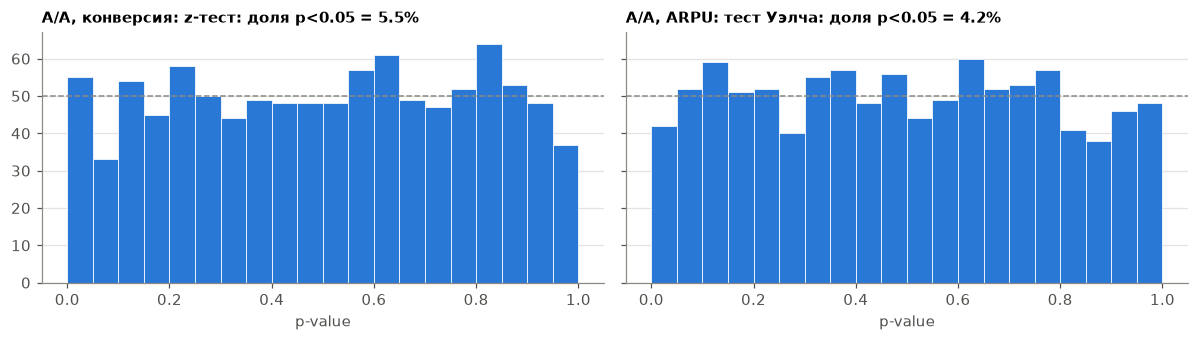

In [6]:
rng = np.random.default_rng(42)
y = control.revenue.to_numpy(dtype=float)
conv = control.converted.to_numpy(dtype=bool)
p_rev, p_conv = [], []
for _ in range(1000):
    mask = rng.random(len(y)) < 0.5
    p_rev.append(st.ttest_ind(y[mask], y[~mask], equal_var=False).pvalue)
    x1, n1, x2, n2 = conv[mask].sum(), mask.sum(), conv[~mask].sum(), (~mask).sum()
    p_conv.append(ab.proportion_test(x1, n1, x2, n2).p_value)
p_rev, p_conv = np.array(p_rev), np.array(p_conv)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, p, title in [(axes[0], p_conv, "конверсия: z-тест"), (axes[1], p_rev, "ARPU: тест Уэлча")]:
    ax.hist(p, bins=20, range=(0, 1), color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axhline(len(p) / 20, color=GRAY, linestyle="--", linewidth=1)
    ax.set_title(f"A/A, {title}: доля p<0.05 = {(p < 0.05).mean():.1%}", fontsize=10)
    ax.set_xlabel("p-value")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 3. Основная метрика: конверсия

In [7]:
conversion = ab.proportion_test(control.converted.sum(), len(control), treatment.converted.sum(), len(treatment),
                                "Конверсия")
print(f"control {conversion.control:.2%}, treatment {conversion.treatment:.2%}")
print(f"Разница {conversion.diff * 100:+.2f} п.п., 95% ДИ [{conversion.ci_low * 100:+.2f}; {conversion.ci_high * 100:+.2f}] п.п. "
      f"(отн. {conversion.rel:+.1%}), p = {conversion.p_value:.4f}")

control 42.26%, treatment 44.90%
Разница +2.64 п.п., 95% ДИ [+0.29; +4.99] п.п. (отн. +6.2%), p = 0.0278


## 4. ARPU: сырой тест, бутстреп и CUPED

Распределение выручки на участника - больше половины нулей и длинный хвост. Сравниваем три оценки одного и того же эффекта:
- **Уэлч** на сырых данных;
- **бутстреп** - без опоры на нормальность, контроль для Уэлча;
- **CUPED** - вычитаем из выручки часть, объяснимую выручкой в предпериоде: `y' = y - theta (x - mean(x))`. Предпериод измерен до воздействия, поэтому оценка эффекта остаётся несмещённой, а дисперсия падает. CUPED заодно корректирует случайный дисбаланс групп в предпериоде, если он есть.

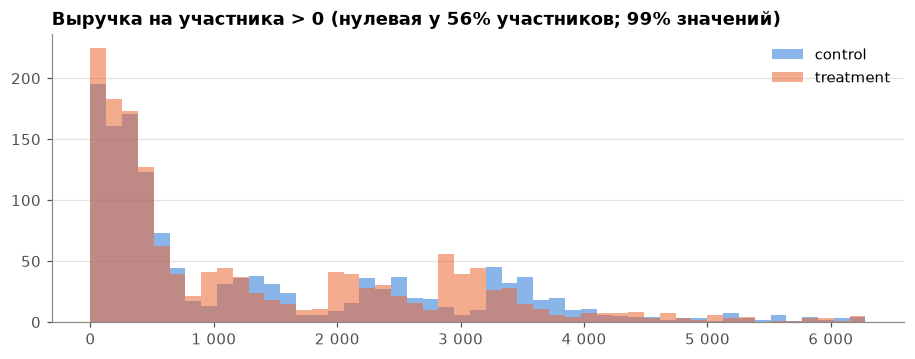

theta = 0.117; дисперсия снизилась на 1.2%; ширина ДИ: 127.2 -> 126.4
Предпериод: control 532.9, treatment 503.8 (-5.4%)


Метод,"Эффект, абс.",95% ДИ,"Эффект, отн.",p-value
ARPU: Уэлч,-3.1,[-66.7; +60.5],-0.5%,0.924
ARPU: бутстреп,-3.1,[-66.2; +60.7],-0.5%,0.913
ARPU: CUPED,+0.3,[-62.9; +63.5],+0.0%,0.993


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.linspace(0, np.quantile(users.revenue, 0.99), 50)
for g, color in [(control, BLUE), (treatment, ORANGE)]:
    ax.hist(g.revenue[g.revenue > 0], bins=bins, color=color, alpha=0.55, label=g.variant.iloc[0])
ax.set_title(f"Выручка на участника > 0 (нулевая у {(users.revenue == 0).mean():.0%} участников; 99% значений)")
money_axis(ax, axis="x")
ax.legend()
ax.grid(axis="x", visible=False)
plt.show()

arpu_raw = ab.welch_test(control.revenue, treatment.revenue, "ARPU: Уэлч")
arpu_boot = ab.bootstrap_test(control.revenue, treatment.revenue, "ARPU: бутстреп")

y_cuped, theta = ab.cuped(users.revenue, users.pre_revenue)
users["revenue_cuped"] = y_cuped
cc, ct = users[users.variant == "control"], users[users.variant == "treatment"]
arpu_cuped = ab.welch_test(cc.revenue_cuped, ct.revenue_cuped, "ARPU: CUPED")
# у CUPED-метрики среднее смещено на константу, относительный эффект считаем к сырому ARPU контроля
arpu_cuped.control = control.revenue.mean()
arpu_cuped.treatment = control.revenue.mean() + arpu_cuped.diff

reduction = 1 - users.revenue_cuped.var() / users.revenue.var()
print(f"theta = {theta:.3f}; дисперсия снизилась на {reduction:.1%}; "
      f"ширина ДИ: {arpu_raw.ci_high - arpu_raw.ci_low:,.1f} -> {arpu_cuped.ci_high - arpu_cuped.ci_low:,.1f}")
print(f"Предпериод: control {control.pre_revenue.mean():,.1f}, treatment {treatment.pre_revenue.mean():,.1f} "
      f"({treatment.pre_revenue.mean() / control.pre_revenue.mean() - 1:+.1%})")

pd.DataFrame([{"Метод": e.metric, "Эффект, абс.": e.diff, "95% ДИ": f"[{e.ci_low:+,.1f}; {e.ci_high:+,.1f}]",
               "Эффект, отн.": e.rel, "p-value": e.p_value} for e in (arpu_raw, arpu_boot, arpu_cuped)]) \
    .style.format({"Эффект, абс.": "{:+,.1f}", "Эффект, отн.": "{:+.1%}", "p-value": "{:.3f}"}).hide(axis="index")

## 5. Средний чек и доля отмен: метрики-отношения

Средний чек = выручка / число покупок. Наивный путь - t-тест по заказам - неверен: рандомизировали клиентов, а не заказы, и заказы одного клиента зависимы. Такой тест занижает дисперсию тем сильнее, чем больше заказов у одного клиента и чем они похожи между собой. Delta-метод считает дисперсию отношения из пользовательских сумм и корректен при любой зависимости. Сравним оба.

In [9]:
aov = ab.ratio_test(control.revenue, control.purchases, treatment.revenue, treatment.purchases, "Средний чек")
cancel = ab.ratio_test(control.cancelled_orders, control.orders, treatment.cancelled_orders, treatment.orders,
                       "Доля отмен")

order_level = query(f"""
    select u.variant as variant, o.order_total as order_total
    from fct_orders as o
    inner join mart_ab_users as u on u.customer_id = o.customer_id
    where o.is_revenue and o.created_at >= u.assigned_at and o.created_at < u.window_end
""")
naive = ab.welch_test(order_level[order_level.variant == "control"].order_total,
                      order_level[order_level.variant == "treatment"].order_total, "Средний чек: t-тест по заказам (неверно)")

pd.DataFrame([{"Метрика": e.metric, "control": e.control, "treatment": e.treatment, "Эффект, отн.": e.rel,
               "95% ДИ, отн.": f"[{e.rel_ci[0]:+.1%}; {e.rel_ci[1]:+.1%}]", "Ширина ДИ, абс.": e.ci_high - e.ci_low,
               "p-value": e.p_value} for e in (aov, naive, cancel)]) \
    .style.format({"control": "{:,.3f}", "treatment": "{:,.3f}", "Эффект, отн.": "{:+.1%}",
                   "Ширина ДИ, абс.": "{:,.3f}", "p-value": "{:.4f}"}).hide(axis="index")

Метрика,control,treatment,"Эффект, отн.","95% ДИ, отн.","Ширина ДИ, абс.",p-value
Средний чек,930.520,816.687,-12.2%,[-18.5%; -6.0%],115.723,0.0001
Средний чек: t-тест по заказам (неверно),930.520,816.687,-12.2%,[-18.5%; -6.0%],115.782,0.0001
Доля отмен,0.143,0.125,-12.5%,[-24.7%; -0.2%],0.035,0.0468


## 6. Сводка

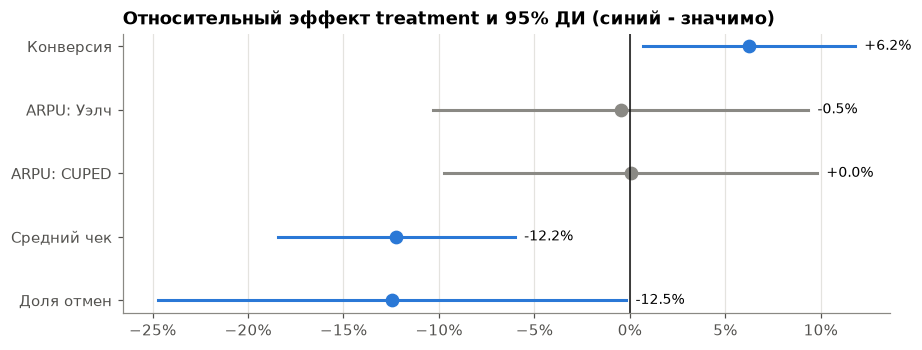

Метрика,control,treatment,"Эффект, отн.",ДИ от,ДИ до,p-value,Значимо
Конверсия,0.423,0.449,+6.2%,+0.7%,+11.8%,0.0278,да
ARPU: Уэлч,646.781,643.666,-0.5%,-10.3%,+9.4%,0.9235,нет
ARPU: CUPED,646.781,647.061,+0.0%,-9.7%,+9.8%,0.9931,нет
Средний чек,930.520,816.687,-12.2%,-18.5%,-6.0%,0.0001,да
Доля отмен,0.143,0.125,-12.5%,-24.7%,-0.2%,0.0468,да


In [10]:
effects = [conversion, arpu_raw, arpu_cuped, aov, cancel]
summary = pd.DataFrame([{"Метрика": e.metric, "control": e.control, "treatment": e.treatment,
                         "Эффект, отн.": e.rel, "ДИ от": e.rel_ci[0], "ДИ до": e.rel_ci[1],
                         "p-value": e.p_value, "Значимо": "да" if e.significant else "нет"} for e in effects])

fig, ax = plt.subplots(figsize=(9, 3.3))
yy = np.arange(len(summary))[::-1]
for y_, (_, row) in zip(yy, summary.iterrows()):
    color = BLUE if row["Значимо"] == "да" else GRAY
    ax.plot([row["ДИ от"], row["ДИ до"]], [y_, y_], color=color, linewidth=2)
    ax.plot(row["Эффект, отн."], y_, "o", color=color, markersize=8)
    ax.annotate(f"{row['Эффект, отн.']:+.1%}", (row["ДИ до"], y_), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.axvline(0, color="#0b0b0b", linewidth=1)
ax.set_yticks(yy, summary["Метрика"])
percent_axis(ax, axis="x")
ax.set_title("Относительный эффект treatment и 95% ДИ (синий - значимо)")
ax.grid(axis="y", visible=False)
plt.show()

summary.style.format({"control": "{:,.3f}", "treatment": "{:,.3f}", "Эффект, отн.": "{:+.1%}", "ДИ от": "{:+.1%}",
                      "ДИ до": "{:+.1%}", "p-value": "{:.4f}"}).hide(axis="index")

## 7. Сверка с заложенными эффектами

Данные синтетические, поэтому «правда» известна: в `backfill.py` для группы treatment в окне эксперимента заложены цена ×0.90, доля неоплаченных заказов 8% вместо 12% и частота повторных покупок ×1.15. Проверяем, что по данным восстанавливаются сами механизмы, - это проверка и анализа, и пайплайна целиком (CDC -> dbt -> витрина).

In [11]:
mech = query(f"""
    with orders_in_window as (
        select o.order_id, o.customer_id, o.status, o.paid_at, o.created_at, o.customer_order_number,
               u.variant, u.window_end
        from fct_orders as o
        inner join mart_ab_users as u on u.customer_id = o.customer_id
        where o.created_at >= u.assigned_at and o.created_at < u.window_end
    )
    select
        variant,
        -- неоплаченные: только заказы, у которых было время дойти до оплаты (старше 9 дней, см. ноутбук 02)
        countIf(status = 'cancelled' and paid_at is null and created_at < window_end - interval 9 day)
            / countIf(created_at < window_end - interval 9 day) as unpaid_share,
        countIf(customer_order_number > 1) as repeat_orders
    from orders_in_window
    group by variant
""").set_index("variant")

prices = query(f"""
    -- цена одного и того же товара в одну и ту же неделю: сравнение групп без влияния изменений цен
    select i.product_id, toMonday(i.order_date) as week, u.variant, avg(i.unit_price) as price
    from fct_order_items as i
    inner join mart_ab_users as u on u.customer_id = i.customer_id
    inner join fct_orders as o on o.order_id = i.order_id
    where o.created_at >= u.assigned_at and o.created_at < u.window_end
    group by i.product_id, week, u.variant
""").pivot_table(index=["product_id", "week"], columns="variant", values="price").dropna()

repeat_per_user = mech.repeat_orders / users.groupby("variant").size()
check = pd.DataFrame({
    "Заложено": ["цена x0.90", "неоплаченных 12% -> 8%", "повторные покупки x1.15"],
    "Оценка по данным": [
        f"цена x{(prices.treatment / prices.control).median():.3f}",
        f"неоплаченных {mech.unpaid_share['control']:.1%} -> {mech.unpaid_share['treatment']:.1%}",
        f"повторные покупки x{repeat_per_user['treatment'] / repeat_per_user['control']:.3f}",
    ],
}, index=["Скидка", "Оплата", "Частота"])
check

,Заложено,Оценка по данным
Скидка,цена x0.90,цена x0.900
Оплата,неоплаченных 12% -> 8%,неоплаченных 11.2% -> 8.2%
Частота,повторные покупки x1.15,повторные покупки x1.154


## 8. Решение: выручка - не прибыль

Формально правило выполнено: конверсия значимо выросла, ARPU значимо не упал. Но правило было сформулировано по выручке, а скидка бьёт по марже: при неизменной выручке клиенты получили на ~11% больше товаров (выручка / 0.9), и себестоимость этих товаров магазин оплатил. Себестоимости в данных нет, поэтому считаем изменение валовой прибыли на клиента для нескольких типичных маржинальностей.

Если до скидки маржа `m`, а выручка на клиента изменилась в `r` раз, то прибыль на клиента меняется в `r * (1 - (1 - m) / 0.9) / m` раз.

In [12]:
DISCOUNT = 0.10
ratio_point = arpu_raw.treatment / arpu_raw.control
ratio_low, ratio_high = 1 + arpu_raw.rel_ci[0], 1 + arpu_raw.rel_ci[1]

def profit_change(revenue_ratio, margin):
    return revenue_ratio * (1 - (1 - margin) / (1 - DISCOUNT)) / margin - 1

margins = [0.2, 0.3, 0.4, 0.5]
pd.DataFrame({
    "Изменение прибыли": [profit_change(ratio_point, m) for m in margins],
    "При нижней границе ДИ ARPU": [profit_change(ratio_low, m) for m in margins],
    "При верхней границе ДИ ARPU": [profit_change(ratio_high, m) for m in margins],
    "Рост ARPU для безубыточности": [m / (m - DISCOUNT) * (1 - DISCOUNT) - 1 if m > DISCOUNT else np.nan for m in margins],
}, index=[f"маржа {m:.0%}" for m in margins]).style.format("{:+.1%}")

,Изменение прибыли,При нижней границе ДИ ARPU,При верхней границе ДИ ARPU,Рост ARPU для безубыточности
маржа 20%,-44.7%,-50.2%,-39.2%,+80.0%
маржа 30%,-26.3%,-33.6%,-19.0%,+35.0%
маржа 40%,-17.1%,-25.3%,-8.9%,+20.0%
маржа 50%,-11.5%,-20.3%,-2.8%,+12.5%


## Выводы и решение

*Данные синтетические (`backfill.py`, seed 42): эффекты заложены в генератор, и это позволяет проверить, что методика их восстанавливает.*

**Эксперименту можно доверять.** Перекоса групп нет (3 391 / 3 441, p = 0.55). В предпериоде группы не различаются ни по конверсии (p = 0.86), ни по ARPU (p = 0.39). В A/A-симуляции z-тест и тест Уэлча дают 5.5% и 4.2% ложных срабатываний при номинале 5%, то есть на этих данных, несмотря на тяжёлый хвост выручки, оба теста корректны.

**Результаты** (treatment против control, 95% ДИ):

| Метрика | Эффект | Вывод |
|---|---|---|
| Конверсия (основная) | +2.6 п.п. (42.3% -> 44.9%), ДИ [+0.3; +5.0] п.п., p = 0.028 | значимо выросла |
| ARPU | -0.5%, ДИ [-10.3%; +9.4%], p = 0.92 | изменение не обнаружено |
| Средний чек | -12.2%, ДИ [-18.5%; -6.0%] | значимо упал: скидка 10% и мелкие заказы новых покупателей |
| Доля отмен (guardrail) | -12.5%, ДИ [-24.7%; -0.2%] | не ухудшилась, даже снизилась |

**Что видно по методике:**
- Эффект на конверсию (+2.6 п.п.) меньше MDE при планировании (3.4 п.п.): мощности хватало впритык, и значимость здесь - отчасти удача. Повторный тест такого размера мог бы её не показать.
- ARPU - слабая метрика для этого теста: MDE около 14%, а ожидаемые эффекты меньше. «Не значимо» здесь означает «тест не различает эффекты в пределах ±10%», а не «эффекта нет».
- CUPED на этих данных не помог: корреляция выручки соседних окон rho = 0.09 даёт снижение дисперсии на 1%. Нужны более сильные ковариаты (CUPAC).
- t-тест по заказам для среднего чека методически неверен, но здесь его интервал почти совпал с delta-методом: у большинства клиентов в окне 1-2 покупки, и зависимость заказов слабая.
- Все три заложенных механизма восстановлены: цена x0.900 (заложено x0.90), неоплаченные 11.2% -> 8.2% (12% -> 8%), повторные покупки x1.154 (x1.15). Значит, корректно работают и анализ, и весь пайплайн от CDC до витрины.

**Решение: скидку на всех клиентов не внедрять.** Правило «конверсия выросла, ARPU не упал» формально выполнено, но оно было сформулировано по выручке, а не по прибыли - это ошибка дизайна, и её стоит признать. При той же выручке клиенты получили примерно на 11% больше товаров, себестоимость которых оплачивает магазин. При марже 30% прибыль на клиента падает примерно на 26%, и даже на верхней границе ДИ ARPU - на 19%. Для безубыточности ARPU должен был бы вырасти на 35%, а тест исключает рост больше 9.4%.

**Следующие шаги:**
1. В следующих экспериментах с ценой основной денежной метрикой должна быть валовая прибыль на клиента, а не выручка. Для этого в хранилище нужна себестоимость товаров.
2. Проверить таргетированную скидку на сегменты, где выигрыш от возврата клиента больше потерь маржи: «Под угрозой» и «Новички» (ноутбук 04).
3. Проверить меньшую скидку или порог («скидка от суммы X»): конверсия может вырасти почти так же при меньших потерях маржи.